In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True)
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional
from keras.optimizers import SGD
from keras.callbacks import History
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard

In [2]:
technique_indicatorttm = np.load('******_ttm.npy',allow_pickle=True)
technique_indicatorpbr = np.load('******_pbr.npy',allow_pickle=True)
technique_indicatorps = np.load('******_ps.npy',allow_pickle=True)
technique_indicatorpcf = np.load('******_pcf.npy',allow_pickle=True)
sample_data = np.concatenate((technique_indicatorttm,technique_indicatorpbr,technique_indicatorps,technique_indicatorpcf),axis=2)
sample_data[pd.isna(sample_data)] = 5
sample_data.shape

(1215, 15, 12)

In [3]:
data = pd.read_csv('******close.csv',index_col=0)

In [4]:
data.shape
#data[pd.isna(data)] = 5
from sklearn.preprocessing import MinMaxScaler
data_scaler = MinMaxScaler(feature_range=(-1, 1))
data_dataset = data_scaler.fit_transform(data)
data_dataset.shape

(1215, 15)

In [5]:
data

,002044.SZ,002173.SZ,002219.SZ,002524.SZ,300015.SZ,300143.SZ,300149.SZ,300244.SZ,300347.SZ,300404.SZ,600645.SH,600721.SH,600763.SH,603127.SH,603882.SH
Date,,,,,,,,,,,,,,,
2018/1/2,21.28,13.20,11.71,6.35,30.30,25.60,15.35,23.51,35.22,19.95,28.40,10.33,31.86,55.98,31.22
2018/1/3,20.50,13.11,11.71,6.35,29.22,25.60,15.35,23.48,34.90,20.13,28.40,10.41,31.62,55.75,32.11
2018/1/4,21.06,13.10,11.71,6.35,29.54,25.60,15.35,23.76,35.05,20.11,28.40,10.43,31.65,54.80,31.23
2018/1/5,21.42,13.05,11.71,6.35,30.41,25.60,15.35,23.80,35.05,20.31,28.40,11.10,32.50,54.80,31.81
2018/1/8,21.49,13.02,11.71,6.35,31.67,25.60,15.35,23.60,34.51,20.87,28.40,11.11,33.80,55.75,32.21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022/12/26,5.15,6.46,3.98,6.80,29.70,9.97,10.22,24.50,95.58,7.94,16.98,6.15,149.18,54.96,68.25
2022/12/27,5.16,6.30,3.99,6.74,29.56,9.84,9.91,24.08,95.70,7.53,16.76,6.04,148.53,55.10,67.69
2022/12/28,5.67,6.38,3.96,6.96,30.40,9.96,10.09,24.51,101.59,7.72,16.80,6.11,149.58,56.50,71.12


In [6]:
p=1
Label_data_2 = data_dataset[p-1:,:]
Label_data_2.shape

(1215, 15)

In [7]:
#input 部分
input_data = sample_data[:,:,:]
input_data.shape

(1215, 15, 12)

In [8]:
input_data_final = np.zeros((sample_data.shape[0]+1-p,p,sample_data.shape[1],sample_data.shape[2]))
input_data_final.shape

(1215, 1, 15, 12)

In [9]:
for i in range(sample_data.shape[0]+1-p):
    one_line = []
    for j in range(p):
        one_line.append(sample_data[i+j])
        
    input_data_final[i] = np.array(one_line)
    

In [10]:
N=15
M=1215
P=1
F=12
TEST_SIZE = 0.3 # the test and val size of dataset
RANDOM_STATE = 4

In [11]:
T = np.load('******stockholder.npy')
I= np.load('******_qa_graph.npy')
S=np.load('******volume_kendall.npy')

In [12]:
 #T = np.random.normal(size=(N,N))
 #I = np.random.normal(size=(N,N))
 #S = np.random.normal(size=(N,N))
 #I=T
 #S=T

In [13]:
Fixed_Matrices = [S,I,T]

In [14]:
samples = input_data_final#np.random.normal(size=(M, P, N, F))
labels = Label_data_2#np.random.normal(size=(M, N))

In [15]:
indices = np.arange(data.shape[0]).reshape(-1, 1)
label_with_index = np.hstack((indices, labels)) 
label_with_index

array([[   0.        ,    0.34811357,    0.6321394 , ...,   -0.98923305,
          -0.77707702,   -0.79776316],
       [   1.        ,    0.2874368 ,    0.61471442, ...,   -0.99050599,
          -0.77986659,   -0.78605263],
       [   2.        ,    0.33099961,    0.61277832, ...,   -0.99034688,
          -0.79138872,   -0.79763158],
       ...,
       [1212.        ,   -0.86619992,   -0.68828654, ...,   -0.36485626,
          -0.77077016,   -0.27276316],
       [1213.        ,   -0.84830805,   -0.68247822, ...,   -0.36793253,
          -0.76822317,   -0.24302632],
       [1214.        ,   -0.84986387,   -0.67279768, ...,   -0.36061313,
          -0.75257732,   -0.21947368]])

In [16]:
x_train, x_test, y_train, y_test = train_test_split(samples,label_with_index, test_size=TEST_SIZE, random_state=RANDOM_STATE)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.33, random_state=RANDOM_STATE)
x_train = tf.constant(x_train,dtype=tf.float32)
y_train = tf.constant(y_train,dtype=tf.float32)
x_test = tf.constant(x_test,dtype=tf.float32)
y_test = tf.constant(y_test,dtype=tf.float32)
x_val = tf.constant(x_val,dtype=tf.float32)
y_val= tf.constant(y_val,dtype=tf.float32)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)

(850, 1, 15, 12) (850, 16)
(244, 1, 15, 12) (244, 16)
(121, 1, 15, 12) (121, 16)


In [17]:
first_column_y_test = y_test[:, 0]
y_test1= y_test[:, 1:]
first_column_y_train = y_train[:, 0]
y_train1= y_train[:, 1:]
y_val1= y_val[:, 1:]
first_column_y_val = y_val[:, 0]
y_val2 = data_scaler.inverse_transform(y_val1)
y_train2=data_scaler.inverse_transform(y_train1)

In [18]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, MultiHeadAttention, LayerNormalization, Dropout
from tensorflow.keras.utils import plot_model

class GATTransformer(tf.keras.Model):
    def __init__(self, N, F, Units_GAT, Units_Transformer, Units_FC,
                 Fixed_Matrices, Matrix_Weights, Is_Dyn,
                 num_heads,
                 dff,
                 dropout_rate=0.1,
                 kernel_initializer='glorot_uniform',
                 bias_initializer='zeros'):
        super(GATTransformer, self).__init__()
        # Number of Nodes
        self.N = N
        # the number of input features
        self.F = F
        # pre-defined matrices: shape=[(N,N),(N,N),(N,N)]
        self.mat = Fixed_Matrices
        
        if Is_Dyn:
            self.mats = self.dyn
        else:
            self.mats = self.add_weight(name='w_Matrices', shape=(self.N, self.N),
                                        initializer=tf.keras.initializers.get(kernel_initializer),
                                        trainable=True)
            for i in range(len(Matrix_Weights)):
                coe = tf.Variable(1.0, trainable=True)
                self.mats = self.mats + Matrix_Weights[i]*self.mat[i]*coe
        
        # GAT_Weights
        self.units_gat = Units_GAT
        self.w_gat = []
        self.a_gat = []
        self.b_gat = []
        pre = self.F
        for i in range(len(self.units_gat)):
            aft = self.units_gat[i]
            w = self.add_weight(name='w_GAT', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_gat.append(w)
            a = self.add_weight(name='a_GAT', shape=(2 * aft, 1),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.a_gat.append(a)
            b = self.add_weight(name='b_GAT', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_gat.append(b)
            pre = aft
        
        # Transformer parameters
        self.units_transformer = Units_Transformer
        self.num_heads = num_heads
        self.dff = dff
        self.dropout_rate = dropout_rate

        # Transformer layers
        self.attention_layers = []
        self.dense_proj_layers = []
        self.norm_layers = []
        self.dropout_layers = []
        for _ in range(len(self.units_transformer)):
            self.attention_layers.append(MultiHeadAttention(num_heads=self.num_heads, key_dim=self.units_transformer[0]))
            self.dense_proj_layers.append(tf.keras.Sequential([
                Dense(self.dff, activation='relu'),
                Dense(self.units_transformer[0])
            ]))
            self.norm_layers.append(LayerNormalization(epsilon=1e-6))
            self.dropout_layers.append(Dropout(self.dropout_rate))
        
        # FC_weights
        self.units_fc = Units_FC
        self.w_fc = []
        self.b_fc = []
        pre = self.units_transformer[-1]
        for i in range(len(self.units_fc)):
            aft = self.units_fc[i]
            w = self.add_weight(name='w_FC', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_fc.append(w)
            b = self.add_weight(name='b_FC', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_fc.append(b)
            pre = aft
    
    def Multi_GAT(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_gat:shape=(None,P,N,C)
        '''
        P = inputs.shape[1]
        x_gat = []
        for t in range(P):
            # (None, P, N, F) =>(None, N, F)
            xt_gat = inputs[:,t,:,:]
            
            # (N,N)*(None, N, F)*(F,C)=> (None, N, C)
            for i in range(len(self.units_gat)):
                xt_gat = self.gat_layer(xt_gat, self.w_gat[i], self.a_gat[i], self.b_gat[i])
            x_gat.append(xt_gat)
        # (None,P,N,C)
        x_gat = tf.stack(x_gat, axis=1)
        return x_gat

    def gat_layer(self, inputs, w, a, b):
        '''
        GAT layer implementation
        inputs: (None,P,N,F)
        w: (F, C)
        a: (2*C, 1)
        b: (C,)
        '''
        h = tf.matmul(inputs, w)  # (None, N, C)
        N = h.shape[1]
        a_input = tf.concat([tf.repeat(h, repeats=N, axis=1), tf.tile(h, [1, N, 1])], axis=-1)
        e = tf.nn.leaky_relu(tf.matmul(a_input, a))  # (None, N*N, 1)
        e = tf.reshape(e, [-1, N, N])  # (None, N, N)
        attention = tf.nn.softmax(e, axis=2)  # (None, N, N)
        h_prime = tf.matmul(attention, h)  # (None, N, C)
        h_prime = h_prime + b
        return tf.nn.elu(h_prime)
    
    def Transformer(self, x, x_gat):
        '''
        x:shape=(None,P,N,F)
        x_gcn:shape=(None,P,N,C)
        x_transformer:shape=(None,N,G)
        '''
        # (None, P, N, F+C)
        x = tf.concat([x, x_gat], axis=-1)

        for attention_layer, dense_proj_layer, norm_layer, dropout_layer in zip(self.attention_layers, self.dense_proj_layers, self.norm_layers, self.dropout_layers):
            attn_output = attention_layer(x, x, x)
            attn_output = dropout_layer(attn_output)
            x = norm_layer(x + attn_output)

            proj_output = dense_proj_layer(x)
            proj_output = dropout_layer(proj_output)
            x = norm_layer(x + proj_output)
        
        x_transformed = tf.reshape(x, (-1, self.N, self.units_transformer[-1]))  # (None, N, units_transformer[-1])
        return x_transformed
    
    def FC(self, x_transformer):
        '''
        x_transformed:shape=(None, N, units_transformer[-1])
        outputs:shape=(None,N,1)
        '''
        x = x_transformer
        for i in range(len(self.w_fc)):
            x = x @ self.w_fc[i] + self.b_fc[i]
            x = tf.nn.sigmoid(x)
        # (None, N)
        x_fc = tf.squeeze(x, axis=-1)
        return x_fc

    def build(self, input_shape):
        super().build(input_shape)
        
    def call(self, inputs):
        '''
        inputs:shape=(None,P,N,F)
        x_fc:shape=(None,N)
        '''
        # (None,P,N,C)
        x_gat = self.Multi_GAT(inputs)
        # (None,N,units_transformer[-1])
        x_transformer = self.Transformer(inputs, x_gat)
        # (None,N)
        x_fc = self.FC(x_transformer)
        return x_fc

In [19]:
# Hyperparameters
N = 15  # Number of nodes
F = 12  # Number of input features

Units_GAT = [16, 32, 64]
Units_Transformer = [76, 76]  # Ensure consistent dimension through all transformer layers
Units_FC = [1]
Matrix_Weights = [1, 1, 1]
Is_Dyn = False
num_heads = 8
dff = 256
#Fixed_Matrices = [tf.random.uniform((N, N)), tf.random.uniform((N, N)), tf.random.uniform((N, N))]

# Model initialization
model = GATTransformer(N, F, Units_GAT, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn,num_heads,dff)
model.build(input_shape=(None,P, N, F))

model.compile(loss='categorical_crossentropy',optimizer='SGD',metrics=[tf.keras.metrics.BinaryAccuracy()])
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath = '******GATTransformer',
    monitor ='val_binary_accuracy',
    save_weights_only = True,
    save_best_only = True)
# Generate model summary
model.summary()

# Generate and save model plot
plot_model(model, to_file='******GATTransformer_model.png', show_shapes=True, show_layer_names=True)

Model: "gat_transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 multi_head_attention (Multi  multiple                 186732    
 HeadAttention)                                                  
                                                                 
 multi_head_attention_1 (Mul  multiple                 186732    
 tiHeadAttention)                                                
                                                                 
 sequential (Sequential)     (None, 1, 15, 76)         39244     
                                                                 
 sequential_1 (Sequential)   (None, 1, 15, 76)         39244     
                                                                 
 layer_normalization (LayerN  multiple                 152       
 ormalization)                                                   
                                                   

AttributeError: module 'pydot' has no attribute 'InvocationException'

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

Epochs = 50
Batch_size = 32
history_list = []
Is_Dyn = False
num_heads = 8
dff = 256

for run in range(8):
    print(f"\n======= Training Round {run+1}/8 =======")

    # 模型初始化（确保 GATTransformer 类正确定义）
    model = GATTransformer(N, F, Units_GAT, Units_Transformer, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn,num_heads,dff)
    model.build(input_shape=(None, P, N, F))
    model.compile(loss='categorical_crossentropy',
                  optimizer='SGD',
                  metrics=[tf.keras.metrics.BinaryAccuracy()])

    # ✅ 日志和模型保存路径
    log_dir = f"******GATTransformer_logs/run{run+1}"
    ckpt_path = f"******GATTransformer_run{run+1}.h5"

    model_ckpt = tf.keras.callbacks.ModelCheckpoint(
        filepath=ckpt_path,
        monitor='val_loss8',
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )
    tb = TensorBoard(log_dir=log_dir, write_graph=True, write_images=True)

    # ✅ 模型训练
    history = model.fit(
        x_train, y_train1,
        batch_size=Batch_size,
        epochs=Epochs,
        validation_data=(x_val, y_val1),
        callbacks=[model_ckpt, tb],
        verbose=1
    )

    history_list.append(history)


======= Training Round 1/8 =======
Epoch 1/50
27/27 [==============================] - 14s 177ms/step - loss: -48.2481 - binary_accuracy: 0.0024 - val_loss: -12.7967 - val_binary_accuracy: 0.0077
Epoch 2/50
27/27 [==============================] - 3s 129ms/step - loss: -48.3642 - binary_accuracy: 0.0037 - val_loss: -12.8019 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 3s 129ms/step - loss: -31.4544 - binary_accuracy: 0.0045 - val_loss: -12.8027 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 4s 131ms/step - loss: -31.5692 - binary_accuracy: 0.0049 - val_loss: -12.8030 - val_binary_accuracy: 0.0000e+00
Epoch 5/50
27/27 [==============================] - 4s 131ms/step - loss: -31.4994 - binary_accuracy: 0.0053 - val_loss: -12.8062 - val_binary_accuracy: 0.0000e+00
Epoch 6/50
27/27 [==============================] - 3s 129ms/step - loss: nan - binary_accuracy: 0.0017 - val_loss: nan - val_binary_accuracy: 0.00

Epoch 26/50
27/27 [==============================] - 3s 125ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 27/50
27/27 [==============================] - 3s 126ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 28/50
27/27 [==============================] - 3s 125ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 29/50
27/27 [==============================] - 3s 127ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 30/50
27/27 [==============================] - 3s 126ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 31/50
27/27 [==============================] - 3s 128ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 32/50
27/27 [===========================


======= Training Round 2/8 =======
Epoch 1/50
27/27 [==============================] - 13s 180ms/step - loss: -65.9344 - binary_accuracy: 0.0017 - val_loss: -74.4656 - val_binary_accuracy: 5.5096e-04
Epoch 2/50
27/27 [==============================] - 4s 132ms/step - loss: -81.3797 - binary_accuracy: 1.5686e-04 - val_loss: -75.0113 - val_binary_accuracy: 5.5096e-04
Epoch 3/50
27/27 [==============================] - 4s 132ms/step - loss: -82.2243 - binary_accuracy: 7.8431e-05 - val_loss: -75.1272 - val_binary_accuracy: 5.5096e-04
Epoch 4/50
27/27 [==============================] - 4s 132ms/step - loss: -81.2926 - binary_accuracy: 1.5686e-04 - val_loss: -75.2659 - val_binary_accuracy: 5.5096e-04
Epoch 5/50
27/27 [==============================] - 4s 132ms/step - loss: -82.4488 - binary_accuracy: 1.5686e-04 - val_loss: -75.8285 - val_binary_accuracy: 5.5096e-04
Epoch 6/50
27/27 [==============================] - 4s 134ms/step - loss: -82.5380 - binary_accuracy: 1.5686e-04 - val_loss: -7

Epoch 25/50
27/27 [==============================] - 4s 134ms/step - loss: -82.4424 - binary_accuracy: 2.3529e-04 - val_loss: -75.5936 - val_binary_accuracy: 5.5096e-04
Epoch 26/50
27/27 [==============================] - 4s 130ms/step - loss: -82.9420 - binary_accuracy: 1.5686e-04 - val_loss: -76.5376 - val_binary_accuracy: 5.5096e-04
Epoch 27/50
27/27 [==============================] - 4s 132ms/step - loss: -83.1333 - binary_accuracy: 2.3529e-04 - val_loss: -76.4890 - val_binary_accuracy: 5.5096e-04
Epoch 28/50
27/27 [==============================] - 3s 127ms/step - loss: -83.3391 - binary_accuracy: 2.3529e-04 - val_loss: -76.7212 - val_binary_accuracy: 5.5096e-04
Epoch 29/50
27/27 [==============================] - 4s 130ms/step - loss: -83.3313 - binary_accuracy: 2.3529e-04 - val_loss: -76.6877 - val_binary_accuracy: 5.5096e-04
Epoch 30/50
27/27 [==============================] - 3s 128ms/step - loss: -83.4561 - binary_accuracy: 2.3529e-04 - val_loss: -76.8811 - val_binary_accurac

Epoch 49/50
27/27 [==============================] - 4s 130ms/step - loss: -83.4859 - binary_accuracy: 2.3529e-04 - val_loss: -76.5588 - val_binary_accuracy: 5.5096e-04
Epoch 50/50
27/27 [==============================] - 4s 132ms/step - loss: -82.8976 - binary_accuracy: 2.3529e-04 - val_loss: -76.0667 - val_binary_accuracy: 5.5096e-04

======= Training Round 3/8 =======
Epoch 1/50
27/27 [==============================] - 13s 175ms/step - loss: -44.9075 - binary_accuracy: 0.0032 - val_loss: -12.8276 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 4s 132ms/step - loss: -60.6429 - binary_accuracy: 8.6275e-04 - val_loss: -12.7962 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 3s 129ms/step - loss: -70.5113 - binary_accuracy: 7.0588e-04 - val_loss: -12.7889 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 4s 131ms/step - loss: -72.1654 - binary_accuracy: 4.7059e-04 - val_loss: 

...

Epoch 46/50
27/27 [==============================] - 3s 123ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 47/50
27/27 [==============================] - 3s 126ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 3s 129ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/27 [==============================] - 4s 131ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 4s 132ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00

======= Training Round 6/8 =======
Epoch 1/50
27/27 [==============================] - 13s 179ms/step - loss: -60.0692 - binary_accuracy: 0.0013 - val_loss: -18.4918 - val_binary_accuracy: 0.0000e+00
Epoc

Epoch 45/50
27/27 [==============================] - 4s 130ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 46/50
27/27 [==============================] - 3s 104ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 47/50
27/27 [==============================] - 3s 123ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 3s 127ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/27 [==============================] - 3s 128ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 3s 128ms/step - loss: nan - binary_accuracy: 7.8431e-05 - val_loss: nan - val_binary_accuracy: 0.0000e+00

======= Training Round 7/8 =======
Epoch 1/50

27/27 [==============================] - 3s 128ms/step - loss: -82.3807 - binary_accuracy: 1.5686e-04 - val_loss: -74.7345 - val_binary_accuracy: 5.5096e-04
Epoch 20/50
27/27 [==============================] - 4s 130ms/step - loss: -82.4659 - binary_accuracy: 1.5686e-04 - val_loss: -75.5821 - val_binary_accuracy: 5.5096e-04
Epoch 21/50
27/27 [==============================] - 3s 127ms/step - loss: -82.7429 - binary_accuracy: 1.5686e-04 - val_loss: -75.4832 - val_binary_accuracy: 5.5096e-04
Epoch 22/50
27/27 [==============================] - 4s 131ms/step - loss: -82.6931 - binary_accuracy: 1.5686e-04 - val_loss: -76.1086 - val_binary_accuracy: 5.5096e-04
Epoch 23/50
27/27 [==============================] - 3s 126ms/step - loss: -82.6735 - binary_accuracy: 1.5686e-04 - val_loss: -75.4979 - val_binary_accuracy: 5.5096e-04
Epoch 24/50
27/27 [==============================] - 4s 131ms/step - loss: -82.5607 - binary_accuracy: 2.3529e-04 - val_loss: -76.0322 - val_binary_accuracy: 5.5096e-0

Epoch 43/50
27/27 [==============================] - 3s 126ms/step - loss: -83.0294 - binary_accuracy: 1.5686e-04 - val_loss: -76.2550 - val_binary_accuracy: 5.5096e-04
Epoch 44/50
27/27 [==============================] - 3s 128ms/step - loss: -83.0624 - binary_accuracy: 1.5686e-04 - val_loss: -76.2318 - val_binary_accuracy: 5.5096e-04
Epoch 45/50
27/27 [==============================] - 3s 128ms/step - loss: -83.0868 - binary_accuracy: 1.5686e-04 - val_loss: -76.1833 - val_binary_accuracy: 5.5096e-04
Epoch 46/50
27/27 [==============================] - 3s 126ms/step - loss: -83.0128 - binary_accuracy: 1.5686e-04 - val_loss: -75.6780 - val_binary_accuracy: 5.5096e-04
Epoch 47/50
27/27 [==============================] - 4s 129ms/step - loss: -83.0556 - binary_accuracy: 1.5686e-04 - val_loss: -76.1866 - val_binary_accuracy: 5.5096e-04
Epoch 48/50
27/27 [==============================] - 3s 128ms/step - loss: -83.0737 - binary_accuracy: 1.5686e-04 - val_loss: -76.5598 - val_binary_accurac

Epoch 42/50
27/27 [==============================] - 4s 143ms/step - loss: -14.1063 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 43/50
27/27 [==============================] - 4s 146ms/step - loss: -14.1062 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 44/50
27/27 [==============================] - 4s 146ms/step - loss: -14.1063 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 45/50
27/27 [==============================] - 4s 137ms/step - loss: -14.1063 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 46/50
27/27 [==============================] - 4s 142ms/step - loss: -14.1062 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 47/50
27/27 [==============================] - 4s 138ms/step - loss: -14.1062 - binary_accuracy: 0.0073 - val_loss: -12.8010 - val_binary_accuracy: 0.0077
Epoch 48/50
27/27 [===============

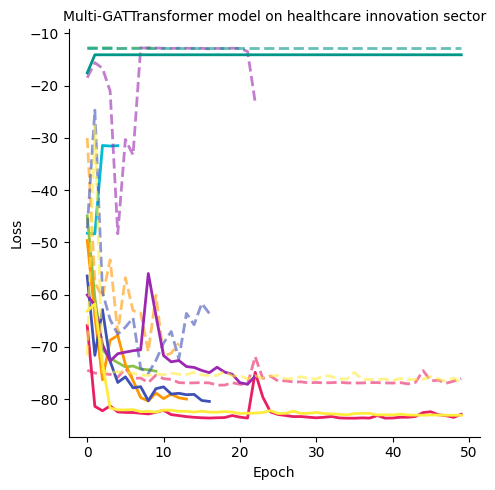

In [21]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']

plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)
#plt.text(0.5, -0.25, '(a)Bank sector', transform=ax.transAxes, fontsize=10, fontweight='bold', ha='center')
plt.title('Multi-GATTransformer model on healthcare innovation sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')
# 去除上右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('******GATTransformer_loss_curve.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

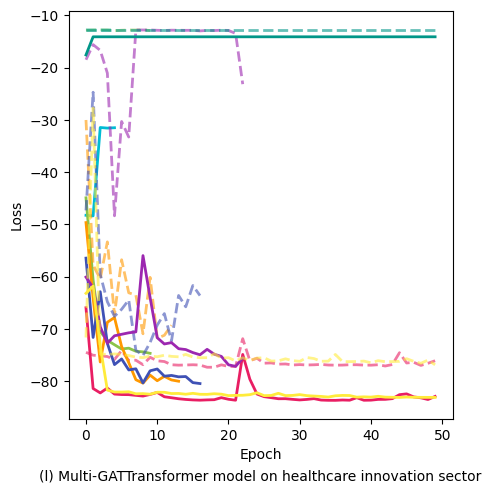

In [22]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']
fig, ax = plt.subplots(figsize=(5, 5))
#plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)

#plt.title('Multi-GCNGRU Model on Bank sector', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.text(0.5, -0.15, '(l) Multi-GATTransformer model on healthcare innovation sector', transform=ax.transAxes, fontsize=10, ha='center')
plt.tight_layout()
plt.savefig('******GATTransformer_loss_curve2.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

8/8 [==============================] - 2s 49ms/step


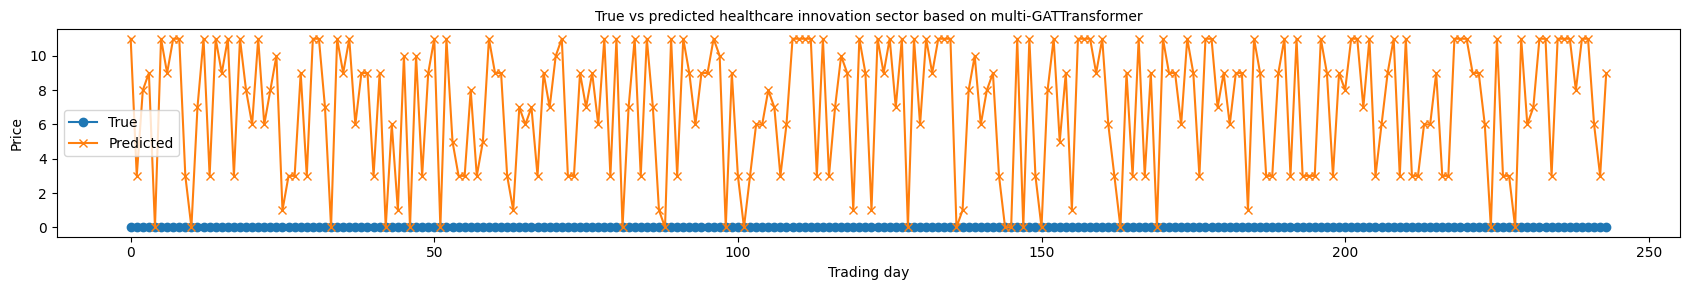

In [23]:
# 加载最佳权重（最后一轮）
model.load_weights('D:/paper/onging/techGATTransformer')

# 预测
y_pred = model.predict(x_test)

# 分类任务处理：若为 one-hot 编码，取最大值索引；否则为二分类阈值判断
if y_pred.shape[-1] > 1:
    y_pred_class = np.argmax(y_pred, axis=-1)
    y_true_class = np.argmax(y_test, axis=-1)
else:
    y_pred_class = (y_pred > 0.5).astype(int)
    y_true_class = y_test

# 绘制对比图
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')
plt.title('True vs predicted healthcare innovation sector based on multi-GATTransformer', fontsize=10)
plt.xlabel('Trading day')
plt.ylabel('Price')
plt.legend()
#plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig('******GATTransformer_pred_vs_true.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [25]:
y_pred1 = pd.DataFrame(y_pred, columns=['002044.SZ', '002173.SZ', '002219.SZ', '002524.SZ',
               '300015.SZ', '300143.SZ', '300149.SZ', '300244.SZ',
               '300347.SZ', '300404.SZ', '600645.SH', '600721.SH',
               '600763.SH', '603127.SH', '603882.SH'])
y_pred1.to_csv('******GATTransformerpredict.csv')
y_pred2 = pd.DataFrame(y_pred_class, columns=['healthGATTransformer'])
y_pred2.to_csv('******GATTransformerpredict2.csv')
